Laboratorul 3 – Partea 3: Loadings, inferență și bonusuri

- Influența features-urilor asupra componentelor principale (loadings), cu reprezentare grafică.
- Descrierea clusterelor în cuvinte proprii, pe baza profilului clusterelor și a vizualizărilor.
- Case inventate, transformate cu același pipeline și același PCA, apoi atribuite unui cluster.
- Bonus a: scatter 3D interactiv pe primele 3 componente, colorat pe clustere, cu centroizi.
- Bonus b: același scatter 3D colorat după cele 6 clase de preț din Lab 2 și comparația cu clusterele.

Folosim preprocesarea din Partea 1 (`preprocess` și `cluster_profile` din `src/lab3_common.py`). Modelul K-Means vine din Partea 2: configurația lui (scalare, prag de varianță, numărul de clustere) este setată într-o singură celulă, mai jos.

In [1]:
# Configurarea cailor: gasim radacina proiectului (folderul cu pyproject.toml),
# ca notebook-ul sa functioneze indiferent de unde este rulat.
import sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Ruleaza notebook-ul din interiorul folderului proiectului (ames-housing-ML)."

DATA_PROCESSED = ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

from common import build_features
from lab3_common import preprocess, cluster_profile

df = pd.read_csv(DATA_PROCESSED / "df.csv")

# Datele din Partea 1: min-max scaling, fara logaritmare, PCA pentru 98% din varianta
X_scaled, y, pipeline = preprocess(df, scaling="minmax", log=False)
pca = PCA(n_components=0.98, svd_solver="full").fit(X_scaled)
X_pca = pca.transform(X_scaled)

print("X_scaled:", X_scaled.shape, "| X_pca:", X_pca.shape)

X_scaled: (2930, 295) | X_pca: (2930, 142)


Influența features-urilor asupra componentelor principale (loadings)

Un loading arată cât de mult contribuie o caracteristică la o componentă principală: `pca.components_` dă direcția fiecărei componente, iar înmulțirea cu `np.sqrt(pca.explained_variance_)` o scalează cu cât de multă varianță explică acea componentă. Un loading mare pozitiv înseamnă că valorile mari ale caracteristicii împing casa spre capătul pozitiv al componentei, iar unul mare negativ, spre capătul negativ.

Componentele sunt 142, iar features-urile 295, deci nu le putem arăta pe toate. Ne uităm la primele 5 componente (aproximativ 30% din varianță) și la features-urile cu cele mai mari loadings pe ele.

Numele coloanelor one-hot au forma `Coloana_valoare` (de exemplu `Foundation_PConc` = fundatie din beton turnat), cu codurile din `AmesExplanations.txt`. In grafice le afisam cu denumiri clare in engleza, cu codul original intre paranteze, folosind functia `pretty` din celula urmatoare.

In [3]:
# Readable feature names (based on AmesExplanations.txt).
# One-hot columns look like "Column_value": the column name and the value code are translated separately.
COLUMN_EN = {
    "Foundation": "Foundation", "Exterior 1st": "Exterior covering", "Exterior 2nd": "Exterior covering (2nd)",
    "Garage Type": "Garage", "House Style": "House style", "MS SubClass": "Dwelling type",
    "MS Zoning": "Zoning", "Mas Vnr Type": "Masonry veneer", "Lot Shape": "Lot shape",
    "Lot Config": "Lot position", "BsmtFin Type 1": "Basement (main finished area)",
    "Bldg Type": "Building type", "Neighborhood": "Neighborhood", "Roof Style": "Roof",
    "Sale Condition": "Sale condition", "Sale Type": "Sale type",
    "Year Built": "Year built", "Year Remod/Add": "Year of remodeling",
    "Garage Yr Blt": "Garage year built", "Garage Finish": "Garage finish (0 = no garage, 3 = finished)",
    "2nd Flr SF": "Second floor area (sq ft)", "Half Bath": "Half bathrooms",
    "Exter Qual": "Exterior quality (Po -> Ex)", "Heating QC": "Heating quality (Po -> Ex)",
    "Fireplace Qu": "Fireplace quality (Po -> Ex)", "Overall Qual": "Overall quality (1-10)",
    "Gr Liv Area": "Living area (sq ft)", "Total Bsmt SF": "Basement area (sq ft)",
    "Land Contour": "Land contour", "Central Air": "Central air conditioning", "Paved Drive": "Paved driveway",
    "Kitchen Qual": "Kitchen quality (Po -> Ex)", "Bsmt Qual": "Basement height quality (Po -> Ex)",
    "Bsmt Exposure": "Basement exposure (0 = none, 4 = good)", "Garage Qual": "Garage quality (Po -> Ex)",
    "Garage Cond": "Garage condition (Po -> Ex)", "Bsmt Cond": "Basement condition (Po -> Ex)",
    "Exter Cond": "Exterior condition (Po -> Ex)", "Pool QC": "Pool quality (Po -> Ex)",
    "Condition 1": "Proximity to", "Heating": "Heating type", "Electrical": "Electrical system",
    "Functional": "Home functionality", "Fence": "Fence", "Alley": "Alley access", "Garage Cars": "Garage size (cars)",
    "Garage Area": "Garage area (sq ft)", "1st Flr SF": "First floor area (sq ft)", "Full Bath": "Full bathrooms",
    "TotRms AbvGrd": "Rooms above ground", "Fireplaces": "Number of fireplaces", "Lot Area": "Lot area (sq ft)",
    "Lot Frontage": "Street frontage (ft)", "Mas Vnr Area": "Masonry veneer area (sq ft)",
    "Overall Cond": "Overall condition (1-10)", "Mo Sold": "Month sold", "Yr Sold": "Year sold",
}
VALUE_EN = {
    "Foundation": {"PConc": "poured concrete", "CBlock": "cinder block", "BrkTil": "brick & tile"},
    "Exterior 1st": {"VinylSd": "vinyl siding", "HdBoard": "hard board", "Wd Sdng": "wood siding",
                     "MetalSd": "metal siding"},
    "Exterior 2nd": {"VinylSd": "vinyl siding", "HdBoard": "hard board", "Wd Sdng": "wood siding",
                     "MetalSd": "metal siding"},
    "Garage Type": {"Attchd": "attached to home", "Detchd": "detached from home", "BuiltIn": "built-in"},
    "House Style": {"1Story": "one story", "2Story": "two story", "1.5Fin": "one and a half story"},
    "MS SubClass": {"20": "1-story, 1946 & newer", "60": "2-story, 1946 & newer",
                    "30": "1-story, 1945 & older", "50": "1.5-story, finished"},
    "MS Zoning": {"RL": "residential, low density", "RM": "residential, medium density",
                  "FV": "residential, Floating Village"},
    "Mas Vnr Type": {"None": "none", "BrkFace": "brick face", "Stone": "stone"},
    "Lot Shape": {"Reg": "regular", "IR1": "slightly irregular", "IR2": "moderately irregular"},
    "Lot Config": {"Inside": "inside lot", "Corner": "corner lot", "CulDSac": "cul-de-sac"},
    "BsmtFin Type 1": {"GLQ": "good living quarters", "Unf": "unfinished", "ALQ": "average living quarters",
                       "None": "no basement"},
    "Bldg Type": {"1Fam": "single-family detached", "TwnhsE": "townhouse end unit", "Twnhs": "townhouse inside unit",
                  "Duplex": "duplex", "2fmCon": "two-family conversion"},
    "Neighborhood": {"NAmes": "North Ames", "OldTown": "Old Town", "CollgCr": "College Creek",
                     "NridgHt": "Northridge Heights", "Somerst": "Somerset", "Gilbert": "Gilbert"},
    "Roof Style": {"Hip": "hip", "Gable": "gable"},
    "Sale Condition": {"Partial": "partial (new house, not completed)", "Normal": "normal"},
    "Sale Type": {"New": "new house", "WD": "warranty deed (standard)"},
    "Land Contour": {"Lvl": "level", "Bnk": "banked", "HLS": "hillside", "Low": "depression"},
    "Central Air": {"Y": "yes", "N": "no"},
    "Paved Drive": {"Y": "paved", "P": "partially paved", "N": "dirt/gravel"},
    "Condition 1": {"Norm": "normal", "Feedr": "feeder street", "Artery": "arterial street",
                    "PosN": "near park/greenbelt", "RRAn": "near railroad"},
    "Heating": {"GasA": "gas forced air", "GasW": "gas hot water"},
    "Electrical": {"SBrkr": "standard circuit breakers", "FuseA": "fuse box (average)"},
    "Functional": {"Typ": "typical", "Min1": "minor deductions"},
    "Fence": {"None": "no fence", "MnPrv": "minimum privacy", "GdPrv": "good privacy"},
    "Alley": {"None": "no alley", "Grvl": "gravel", "Pave": "paved"},
}


def pretty(name):
    """'Foundation_PConc' -> 'Foundation: poured concrete (PConc)'; numeric columns get only a readable name."""
    if name in COLUMN_EN:
        return COLUMN_EN[name]
    for col in sorted(COLUMN_EN, key=len, reverse=True):
        if name.startswith(col + "_"):
            code = name[len(col) + 1:]
            return f"{COLUMN_EN[col]}: {VALUE_EN.get(col, {}).get(code, code)} ({code})"
    return name


print(pretty("Foundation_PConc"), "|", pretty("MS SubClass_20"), "|", pretty("Year Remod/Add"))

Foundation: poured concrete (PConc) | Dwelling type: 1-story, 1946 & newer (20) | Year of remodeling


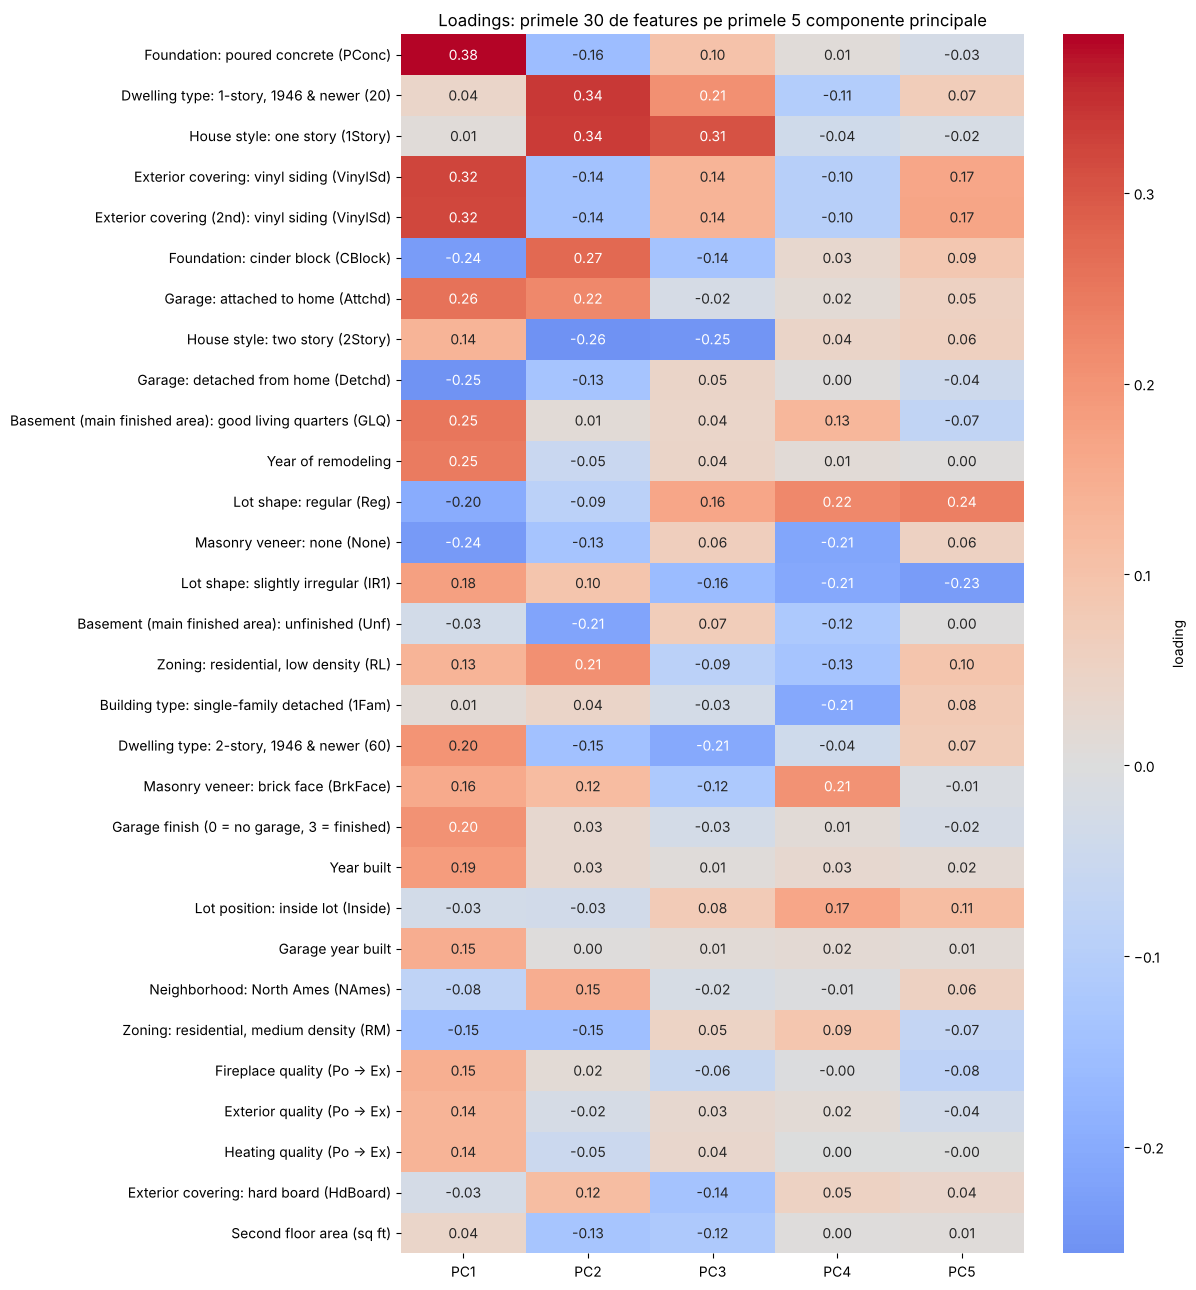

Varianta explicata: {'PC1': np.float64(0.114), 'PC2': np.float64(0.072), 'PC3': np.float64(0.045), 'PC4': np.float64(0.036), 'PC5': np.float64(0.031)}


In [4]:
pc_names = [f"PC{i + 1}" for i in range(pca.n_components_)]
loadings = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_),
                        index=X_scaled.columns, columns=pc_names)

top_pcs = pc_names[:5]
# features-urile cu cel mai mare loading (in valoare absoluta) pe oricare dintre primele 5 componente
top_features = loadings[top_pcs].abs().max(axis=1).sort_values(ascending=False).head(30).index

heat = loadings.loc[top_features, top_pcs].rename(index=pretty)
plt.figure(figsize=(12, 13))
sns.heatmap(heat, cmap="coolwarm", center=0, annot=True, fmt=".2f", cbar_kws={"label": "loading"})
plt.title("Loadings: primele 30 de features pe primele 5 componente principale")
plt.ylabel("")
plt.tight_layout()
plt.show()

print("Varianta explicata:", {pc: round(v, 3) for pc, v in zip(top_pcs, pca.explained_variance_ratio_[:5])})

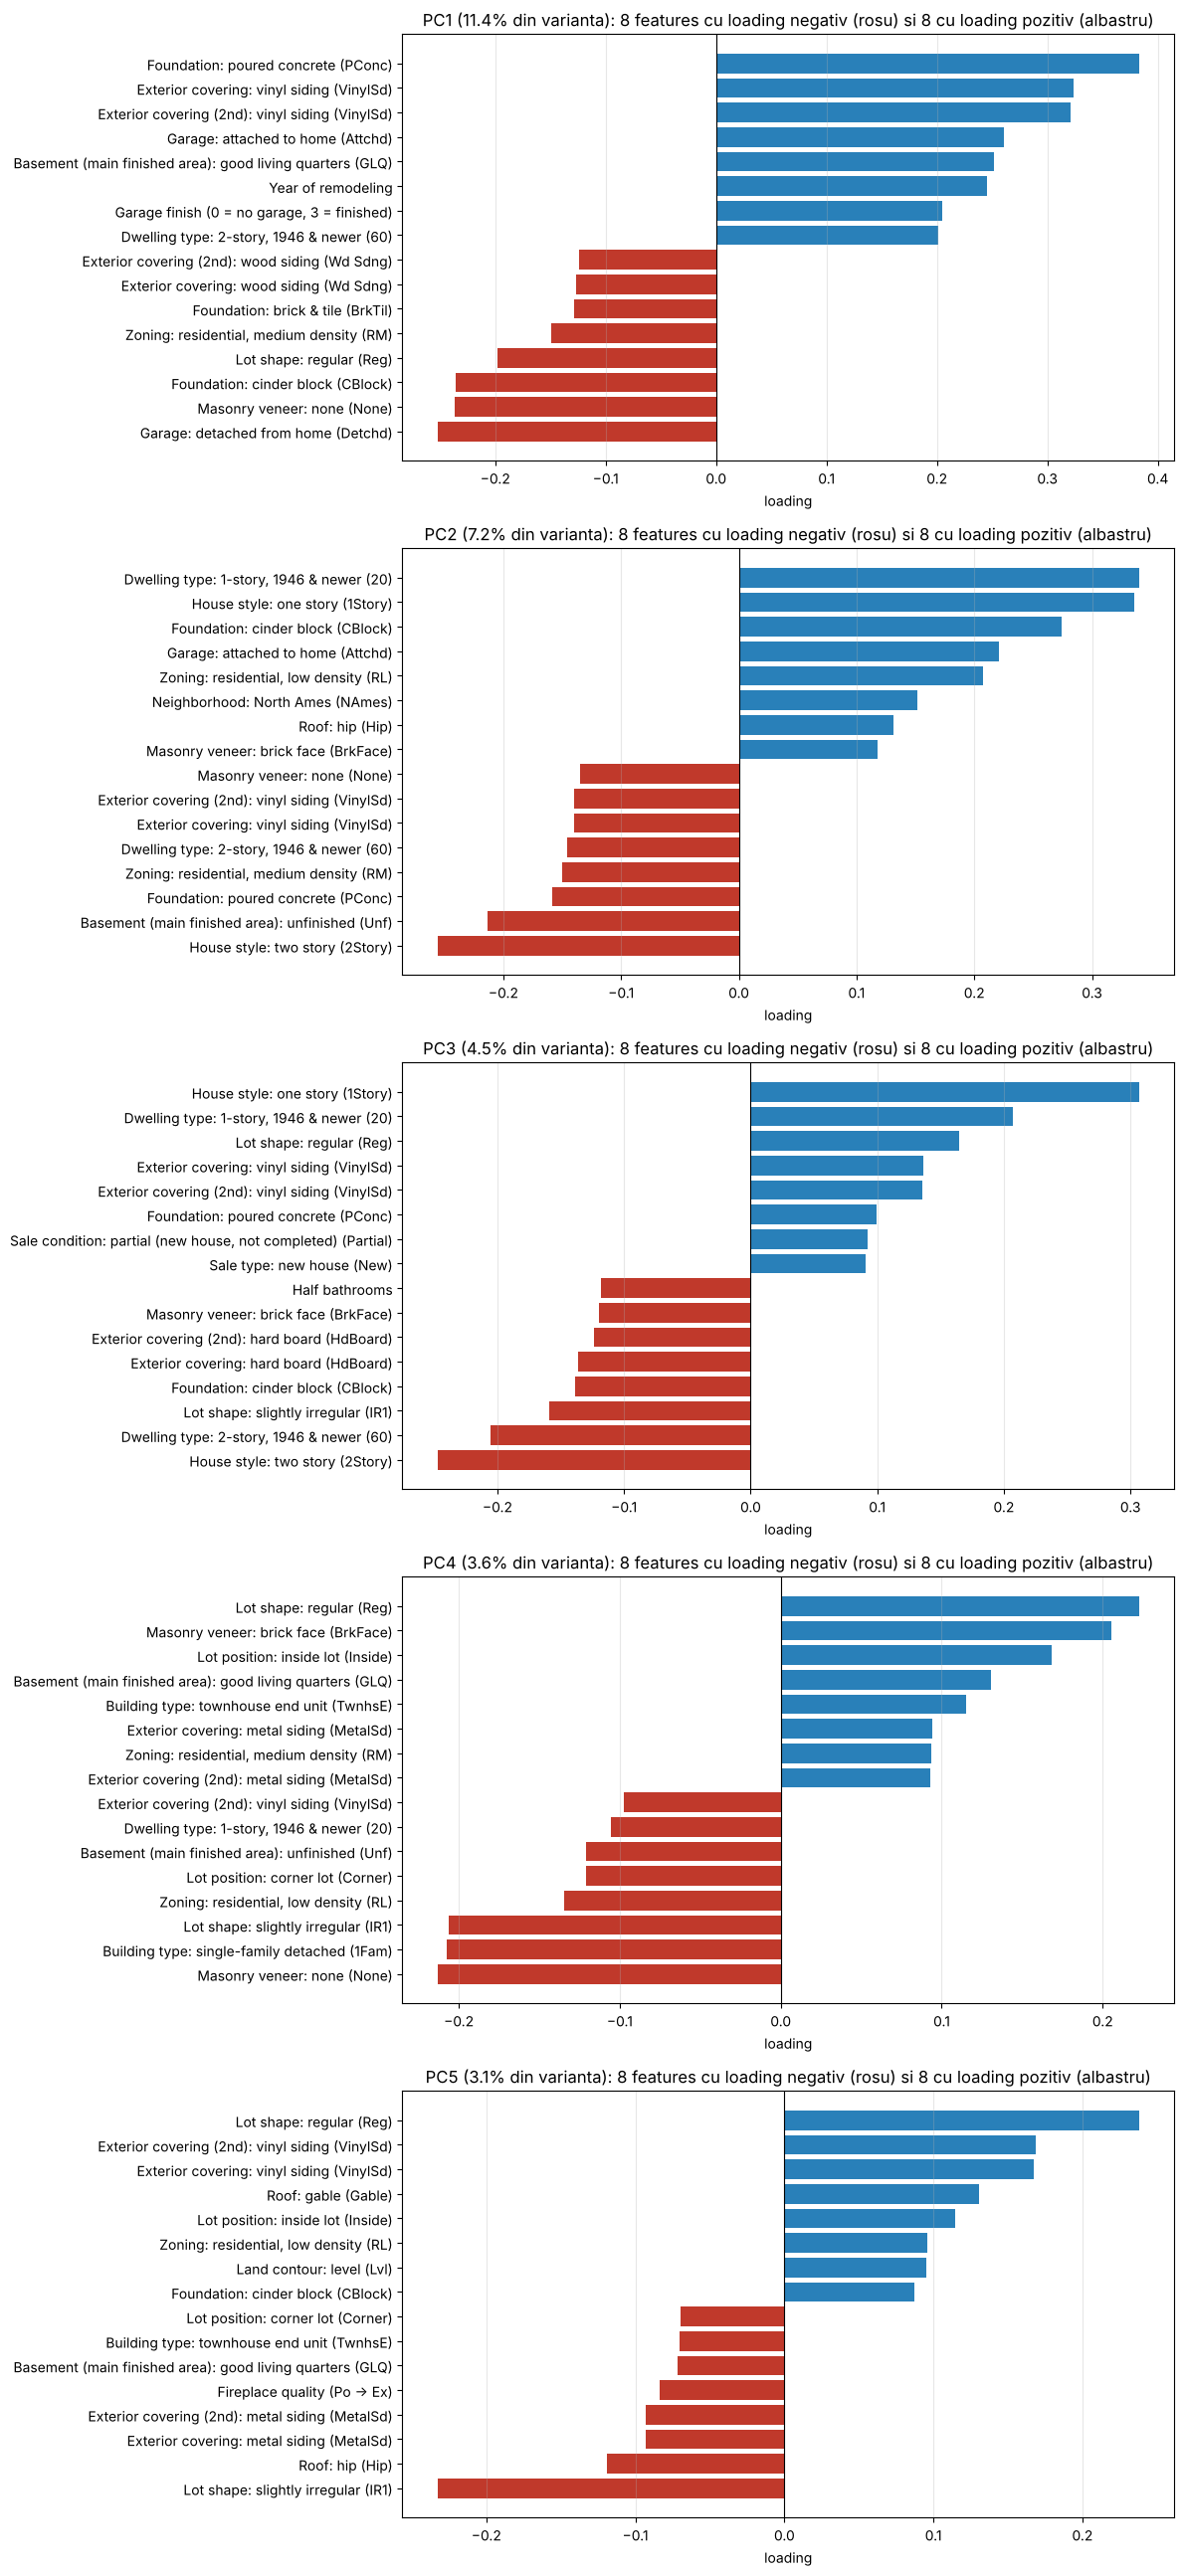

In [5]:
pcs_to_show = ["PC1", "PC2", "PC3", "PC4", "PC5"]
fig, axes = plt.subplots(len(pcs_to_show), 1, figsize=(12, 5.2 * len(pcs_to_show)))
for ax, pc in zip(axes, pcs_to_show):
    s = loadings[pc].sort_values()
    s = pd.concat([s.head(8), s.tail(8)])
    ax.barh([pretty(f) for f in s.index], s.values, color=["#c0392b" if v < 0 else "#2980b9" for v in s.values])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{pc} ({pca.explained_variance_ratio_[int(pc[2:]) - 1]:.1%} din varianta): "
                 "8 features cu loading negativ (rosu) si 8 cu loading pozitiv (albastru)")
    ax.set_xlabel("loading")
    ax.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

Interpretarea loadings

PC1 explică 11,4% din varianță și separă casele noi de cele vechi. La capătul pozitiv sunt fundația din beton turnat (`Foundation_PConc`, loading 0,38), sidingul de vinil (`Exterior 1st/2nd_VinylSd`, 0,32), garajul atașat (0,26), subsolul finisat de calitate bună (`BsmtFin Type 1_GLQ`, 0,25) și anul renovării (0,25). La capătul negativ sunt garajul separat de casă (`Detchd`, -0,25), lipsa placării cu piatră sau cărămidă (-0,24), fundația din blocuri de beton (`CBlock`, -0,24) și fundația din cărămidă (`BrkTil`), tipice caselor construite înainte de 1970. PC1 este deci o axă „modern – vechi”.

PC2 (7,2%) separă casele după numărul de niveluri. Pozitiv: casele cu un singur nivel (`House Style_1Story`, 0,34, și `MS SubClass_20`, 0,34), cu fundație din blocuri și garaj atașat, adică casele tipice din anii 1950–1970, cum sunt cele din NAmes. Negativ: casele cu etaj (`House Style_2Story`, -0,26, `MS SubClass_60`) și subsolul nefinisat.

PC3 (4,5%) combină din nou numărul de niveluri cu vechimea, în sens invers față de PC2: casele noi cu un nivel (`1Story`, `PConc`, `VinylSd`) au valori pozitive, iar casele mai vechi cu etaj (`2Story`, `CBlock`, `HdBoard`) negative.

PC4 (3,6%) separă tipul clădirii și forma lotului. Pozitiv: lotul regulat (`Lot Shape_Reg`, 0,22), placarea fațadei cu cărămidă aparentă (`Mas Vnr Type_BrkFace`, 0,21), lotul în interiorul străzii (`Lot Config_Inside`, 0,17), townhouse-urile de capăt (`Bldg Type_TwnhsE`, 0,11) și zonele rezidențiale cu densitate medie (`MS Zoning_RM`). Negativ: casele unifamiliale izolate (`Bldg Type_1Fam`, -0,21), fără placare decorativă (-0,21), pe loturi ușor neregulate (`Lot Shape_IR1`, -0,21), în zone cu densitate mică (`MS Zoning_RL`, -0,13) și pe colț de stradă (`Lot Config_Corner`). PC4 opune deci locuințele înșiruite, pe loturi regulate și mai dense, caselor individuale pe loturi mai mari și neregulate.

PC5 (3,1%) descrie mai ales forma lotului și acoperișul. Pozitiv: lotul regulat (`Lot Shape_Reg`, 0,24), sidingul de vinil (0,17), acoperișul în două ape (`Roof Style_Gable`, 0,13) și terenul plat (`Land Contour_Lvl`). Negativ: lotul ușor neregulat (`Lot Shape_IR1`, -0,23), acoperișul în patru ape (`Roof Style_Hip`, -0,12) și sidingul metalic. Spre deosebire de primele trei componente, PC4 și PC5 nu mai descriu tipul general al casei, ci detalii ale lotului și ale exteriorului, și explică fiecare puțin peste 3% din varianță.

Un rezultat important: 22 din cele 30 de features din heatmap sunt coloane one-hot, iar printre celelalte 8 nu apare nicio suprafață în afară de `2nd Flr SF`. `Gr Liv Area` are pe PC1 un loading de doar 0,04. Cauza este scalarea min-max: o coloană one-hot are valori 0 sau 1, deci o varianță de până la 0,25 (`Foundation_PConc`: 0,247), în timp ce o variabilă continuă precum `Gr Liv Area` are majoritatea caselor într-o zonă îngustă și câteva valori foarte mari, deci după scalare o varianță mică (0,009). PCA caută direcțiile cu cea mai mare varianță, așa că primele componente sunt construite din variabilele categorice. Tot de aceea sunt necesare 142 de componente pentru 98% din varianță: sunt multe coloane one-hot, slab corelate între ele, și fiecare aduce puțină varianță proprie.

Bonus b (partea 1): primele 3 componente colorate după clasele de preț

`preprocess` întoarce și `y`, clasa de preț din Lab 2 (0 = sub 100k, ..., 5 = peste 400k). Prețul nu a intrat în PCA, deci graficul arată dacă structura găsită de PCA, fără să știe prețul, separă totuși casele scumpe de cele ieftine. Graficul este interactiv: se poate roti și mări.

In [6]:
class_names = ["<100k", "100-130k", "130-180k", "180-250k", "250-400k", ">=400k"]
# cea mai scumpa clasa albastru, a doua verde, apoi spre rosu pentru cele ieftine
class_colors = {">=400k": "#1f4e9c", "250-400k": "#2ca02c", "180-250k": "#bcbd22",
                "130-180k": "#ff7f0e", "100-130k": "#d62728", "<100k": "#7f1d1d"}

pcs3 = pd.DataFrame(X_pca[:, :3], columns=["PC1", "PC2", "PC3"])
pcs3["clasa_pret"] = pd.Categorical([class_names[c] for c in y], categories=class_names[::-1], ordered=True)

fig = px.scatter_3d(pcs3.sort_values("clasa_pret"), x="PC1", y="PC2", z="PC3", color="clasa_pret",
                    color_discrete_map=class_colors, opacity=0.6,
                    title="Primele 3 componente principale, colorate dupa clasa de pret")
fig.update_traces(marker=dict(size=3))
fig.update_layout(height=650, legend_title_text="clasa de pret")
fig.show()

print("Media PC1, PC2, PC3 pe clase de pret:")
display(pcs3.groupby("clasa_pret", observed=True)[["PC1", "PC2", "PC3"]].mean().round(3))
print("Corelatia Spearman dintre clasa de pret si fiecare componenta:")
print(pd.Series({pc: pd.Series(y).corr(pcs3[pc], method="spearman") for pc in ["PC1", "PC2", "PC3"]}).round(3))

Media PC1, PC2, PC3 pe clase de pret:


,PC1,PC2,PC3
clasa_pret,,,
>=400k,1.785,0.021,0.118
250-400k,1.335,-0.028,0.038
180-250k,0.868,-0.096,-0.087
130-180k,-0.308,0.198,-0.126
100-130k,-1.131,-0.016,0.149
<100k,-1.456,-0.514,0.389


Corelatia Spearman dintre clasa de pret si fiecare componenta:
PC1    0.775
PC2    0.033
PC3   -0.119
dtype: float64


Interpretarea graficului colorat după clasele de preț

Deși prețul nu a intrat în PCA, clasele de preț se ordonează clar de-a lungul PC1: media PC1 crește monoton de la -1,46 (sub 100k) la 1,79 (peste 400k), iar corelația Spearman dintre clasa de preț și PC1 este 0,78. PC2 și PC3 aproape nu au legătură cu prețul (corelații 0,03 și -0,12).

Explicația vine din loadings: PC1 măsoară cât de nouă și modernă este o casă (fundație din beton turnat, siding de vinil, garaj atașat, renovare recentă), iar casele noi sunt în general mai scumpe. Numărul de niveluri (PC2) contează mult pentru structura datelor, dar nu și pentru preț: există case scumpe și ieftine și cu un nivel, și cu etaj.

În grafic, clasele vecine se suprapun mult. PC1 separă bine extremele (casele sub 100k de cele peste 400k), dar nu și clasele din mijloc, pentru că prețul depinde și de suprafață și calitate, care au loadings mici în primele componente din cauza scalării min-max.

Modelul K-Means din Partea 2

Toate celulele de mai jos (clustere, case noi, bonusuri) folosesc modelul din celula următoare. K-Means cu același `random_state` dă exact aceleași clustere oricui îl rulează, deci ajunge să setăm aici aceleași valori ca în Partea 2: scalarea, logaritmarea, pragul de varianță și numărul de clustere. După ce aceste valori se schimbă, se rulează din nou notebook-ul de aici în jos.

In [7]:
# ---- CONFIGURATIA DIN PARTEA 2 (de actualizat cu valorile alese acolo) ----
SCALING = "minmax"      # "minmax" sau "standard"
LOG = False             # logaritmarea features-urilor asimetrice
VAR_THRESHOLD = 0.98    # pragul de varianta pastrat de PCA
K = 4                   # numarul optim de clustere (PROVIZORIU, pana la rezultatul din Partea 2)

X_km, _, pipeline_km = preprocess(df, scaling=SCALING, log=LOG)
pca_km = PCA(n_components=VAR_THRESHOLD, svd_solver="full").fit(X_km)
X_km_pca = pca_km.transform(X_km)

kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_km_pca)
labels = kmeans.labels_

print(f"{SCALING}, log={LOG}, {VAR_THRESHOLD:.0%} varianta -> {pca_km.n_components_} componente, K = {K}")
print("Case per cluster:", np.bincount(labels))

minmax, log=False, 98% varianta -> 142 componente, K = 4
Case per cluster: [ 556  571  783 1020]


Profilul clusterelor

`cluster_profile` (Partea 1) calculează, pe valorile originale nescalate, numărul de case și media features-urilor numerice din fiecare cluster. Pentru că primele componente sunt dominate de variabile categorice (fundație, tipul garajului, numărul de niveluri), afișăm și categoria cea mai frecventă din fiecare cluster pentru câteva variabile categorice importante. Prețul nu a fost folosit la clustering, dar îl afișăm ca să vedem dacă clusterele diferă și ca preț.

In [8]:
profile = cluster_profile(df, labels)
key_numeric = ["n_houses", "SalePrice", "Gr Liv Area", "Total Bsmt SF", "Overall Qual", "Year Built",
               "Year Remod/Add", "Garage Cars", "Full Bath", "Lot Area"]
display(profile[key_numeric].round(1))

key_categorical = ["Neighborhood", "House Style", "Foundation", "Garage Type", "Exterior 1st", "MS Zoning"]
modes = pd.DataFrame({
    col: df.groupby(labels)[col].agg(lambda s: f"{s.mode().iloc[0]} ({(s == s.mode().iloc[0]).mean():.0%})")
    for col in key_categorical
})
modes.index.name = "cluster"
display(modes)

,n_houses,SalePrice,Gr Liv Area,Total Bsmt SF,Overall Qual,Year Built,Year Remod/Add,Garage Cars,Full Bath,Lot Area
cluster,,,,,,,,,,
0,556,242600.7,1989.7,1017.5,7.1,1998.1,1999.6,2.3,2.0,11345.4
1,571,242834.8,1523.9,1498.6,7.4,2002.7,2003.3,2.3,1.8,9518.4
2,783,125554.8,1376.2,749.5,5.2,1937.2,1971.7,1.3,1.3,7817.6
3,1020,154782.8,1313.8,1050.9,5.5,1965.4,1974.9,1.6,1.3,11636.4


,Neighborhood,House Style,Foundation,Garage Type,Exterior 1st,MS Zoning
cluster,,,,,,
0,Gilbert (24%),2Story (94%),PConc (93%),Attchd (69%),VinylSd (76%),RL (91%)
1,CollgCr (23%),1Story (96%),PConc (99%),Attchd (93%),VinylSd (75%),RL (81%)
2,OldTown (29%),1.5Fin (35%),BrkTil (39%),Detchd (70%),MetalSd (30%),RM (51%)
3,NAmes (38%),1Story (74%),CBlock (90%),Attchd (72%),HdBoard (31%),RL (98%)


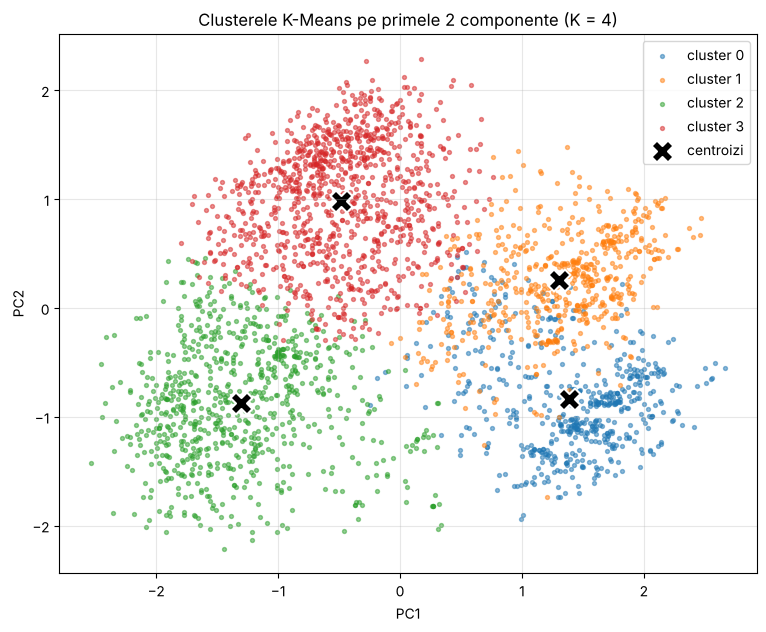

In [9]:
plt.figure(figsize=(9, 7))
for k in range(K):
    m = labels == k
    plt.scatter(X_km_pca[m, 0], X_km_pca[m, 1], s=8, alpha=0.5, label=f"cluster {k}")
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker="X", s=250,
            c="black", edgecolors="white", linewidths=1.5, label="centroizi")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"Clusterele K-Means pe primele 2 componente (K = {K})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Descrierea clusterelor

Atenție: descrierea de mai jos este pentru configurația provizorie (min-max, 98% din varianță, K = 4). Dacă Partea 2 alege alt număr de clustere sau altă scalare, configurația din celula de mai sus se actualizează și descrierea trebuie verificată din nou.

- Clusterul 0 (556 de case): case noi cu etaj. 94% sunt `2Story`, construite în medie în 1998, cu fundație din beton turnat (93%), siding de vinil și cea mai mare suprafață locuibilă (1990 sq ft în medie), dar cu subsol mai mic (1018 sq ft), pentru că suprafața e împărțită pe două niveluri. Calitate generală 7,1, preț median 219.500.
- Clusterul 1 (571 de case): case noi cu un singur nivel. 96% sunt `1Story`, construite în medie în 2003, aproape toate cu fundație din beton turnat (99%) și garaj atașat (93%). Au cea mai bună calitate (7,4) și cel mai mare subsol (1499 sq ft). Preț median 221.370, practic același cu clusterul 0.
- Clusterul 2 (783 de case): case vechi, de dinainte de război. Construite în medie în 1937, cu fundație din cărămidă (`BrkTil`) sau blocuri, garaj separat de casă (70%), adesea cu un etaj și jumătate (`1.5Fin`, 35%) și în zone cu densitate mai mare (`RM`, 51%). Cel mai frecvent cartier este OldTown (29%). Au calitatea cea mai mică (5,2), subsolul cel mai mic și prețul median cel mai mic (122.500).
- Clusterul 3 (1020 de case, cel mai mare): case cu un nivel din anii 1950–1970. Construite în medie în 1965, cu fundație din blocuri de beton (90%), garaj atașat și siding din plăci fibrolemnoase (`HdBoard`). Cartierul tipic este NAmes (38%). Calitate medie (5,5), preț median 145.000.

Clusterele corespund exact celor două axe găsite de PCA: PC1 (nou – vechi) separă clusterele 0 și 1 de clusterele 2 și 3, iar PC2 (un nivel – etaj) separă clusterul 0 de 1 și clusterul 3 de 2. K-Means a grupat casele după epoca construcției și tipul clădirii, nu după preț sau mărime.

Case noi, inventate

Construim câteva case plauzibile pornind de la o casă reală tipică (cea mai apropiată de mediana datelor) și schimbând caracteristicile care contează: suprafața, calitatea, anul construcției, cartierul, numărul de niveluri, fundația, exteriorul și garajul. Pentru fiecare casă ne întrebăm înainte în ce cluster ar trebui să ajungă, apoi o dăm modelului.

O casă nouă trebuie trecută prin exact aceiași pași ca datele de antrenare: `build_features` (aceleași completări și coloane), pipeline-ul de encoding și scalare deja antrenat (doar `transform`, nu `fit`) și PCA-ul deja antrenat. Modelul K-Means a fost antrenat în spațiul componentelor principale: centroizii lui au câte o coordonată pentru fiecare componentă, nu pentru fiecare coloană originală. O casă dată în coloanele originale nu ar avea nici același număr de dimensiuni, nici aceeași scară, deci distanța până la centroizi nu ar avea sens.

In [10]:
# casa reala cea mai apropiata de mediana (pe cateva coloane numerice) = baza pentru casele inventate
num_cols = ["Gr Liv Area", "Total Bsmt SF", "Overall Qual", "Year Built", "Lot Area", "Garage Cars"]
z = (df[num_cols] - df[num_cols].median()) / df[num_cols].std()
base = df.loc[[z.abs().sum(axis=1).idxmin()]].copy()


def make_house(name, **changes):
    house = base.copy()
    for col, value in changes.items():
        house[col] = value
    house.index = [name]
    return house


new_houses = pd.concat([
    make_house("Casa veche mica (OldTown, 1925)",
               **{"Neighborhood": "OldTown", "MS SubClass": 30, "MS Zoning": "RM", "House Style": "1Story",
                  "Year Built": 1925, "Year Remod/Add": 1965, "Garage Yr Blt": 1940, "Overall Qual": 4,
                  "Overall Cond": 5, "Gr Liv Area": 850, "1st Flr SF": 850, "2nd Flr SF": 0,
                  "Total Bsmt SF": 700, "Foundation": "BrkTil", "Exterior 1st": "Wd Sdng",
                  "Exterior 2nd": "Wd Sdng", "Mas Vnr Type": "None", "Mas Vnr Area": 0,
                  "Garage Type": "Detchd", "Garage Cars": 1, "Garage Area": 240, "Kitchen Qual": "Fa",
                  "Exter Qual": "TA", "Full Bath": 1, "Half Bath": 0, "TotRms AbvGrd": 5, "Lot Area": 6000}),
    make_house("Casa tipica anii '60 (NAmes, 1965)",
               **{"Neighborhood": "NAmes", "MS SubClass": 20, "MS Zoning": "RL", "House Style": "1Story",
                  "Year Built": 1965, "Year Remod/Add": 1965, "Garage Yr Blt": 1965, "Overall Qual": 5,
                  "Gr Liv Area": 1150, "1st Flr SF": 1150, "2nd Flr SF": 0, "Total Bsmt SF": 1100,
                  "Foundation": "CBlock", "Exterior 1st": "HdBoard", "Exterior 2nd": "HdBoard",
                  "Garage Type": "Attchd", "Garage Cars": 1, "Garage Area": 300, "Kitchen Qual": "TA",
                  "Exter Qual": "TA", "Full Bath": 1, "TotRms AbvGrd": 6, "Lot Area": 9500}),
    make_house("Casa noua cu un nivel (Somerst, 2006)",
               **{"Neighborhood": "Somerst", "MS SubClass": 20, "MS Zoning": "FV", "House Style": "1Story",
                  "Year Built": 2006, "Year Remod/Add": 2006, "Garage Yr Blt": 2006, "Overall Qual": 7,
                  "Gr Liv Area": 1500, "1st Flr SF": 1500, "2nd Flr SF": 0, "Total Bsmt SF": 1500,
                  "Foundation": "PConc", "Exterior 1st": "VinylSd", "Exterior 2nd": "VinylSd",
                  "Garage Type": "Attchd", "Garage Cars": 2, "Garage Area": 550, "Kitchen Qual": "Gd",
                  "Exter Qual": "Gd", "Full Bath": 2, "TotRms AbvGrd": 6, "Lot Area": 8000}),
    make_house("Casa noua mare cu etaj (NridgHt, 2007)",
               **{"Neighborhood": "NridgHt", "MS SubClass": 60, "MS Zoning": "RL", "House Style": "2Story",
                  "Year Built": 2007, "Year Remod/Add": 2007, "Garage Yr Blt": 2007, "Overall Qual": 9,
                  "Gr Liv Area": 2800, "1st Flr SF": 1450, "2nd Flr SF": 1350, "Total Bsmt SF": 1450,
                  "Foundation": "PConc", "Exterior 1st": "VinylSd", "Exterior 2nd": "VinylSd",
                  "Mas Vnr Type": "Stone", "Mas Vnr Area": 300, "Garage Type": "BuiltIn", "Garage Cars": 3,
                  "Garage Area": 800, "Kitchen Qual": "Ex", "Exter Qual": "Ex", "Full Bath": 3, "Half Bath": 1,
                  "TotRms AbvGrd": 10, "Fireplaces": 1, "Lot Area": 12000}),
])
# build_features cere coloana SalePrice; pretul casei inventate nu intra in features, deci punem o valoare oarecare
new_houses["SalePrice"] = 0
new_houses["Order"] = 0
new_houses["PID"] = 0

display(new_houses[["Neighborhood", "House Style", "Year Built", "Overall Qual", "Gr Liv Area",
                    "Foundation", "Garage Type", "Garage Cars"]])

,Neighborhood,House Style,Year Built,Overall Qual,Gr Liv Area,Foundation,Garage Type,Garage Cars
"Casa veche mica (OldTown, 1925)",OldTown,1Story,1925,4,850,BrkTil,Detchd,1
"Casa tipica anii '60 (NAmes, 1965)",NAmes,1Story,1965,5,1150,CBlock,Attchd,1
"Casa noua cu un nivel (Somerst, 2006)",Somerst,1Story,2006,7,1500,PConc,Attchd,2
"Casa noua mare cu etaj (NridgHt, 2007)",NridgHt,2Story,2007,9,2800,PConc,BuiltIn,3


,cluster,PC1,PC2,distanta la centroid
"Casa veche mica (OldTown, 1925)",2,-1.69,-0.54,3.22
"Casa tipica anii '60 (NAmes, 1965)",3,-0.44,1.73,2.83
"Casa noua cu un nivel (Somerst, 2006)",1,1.01,0.27,3.08
"Casa noua mare cu etaj (NridgHt, 2007)",0,1.32,-1.10,3.16


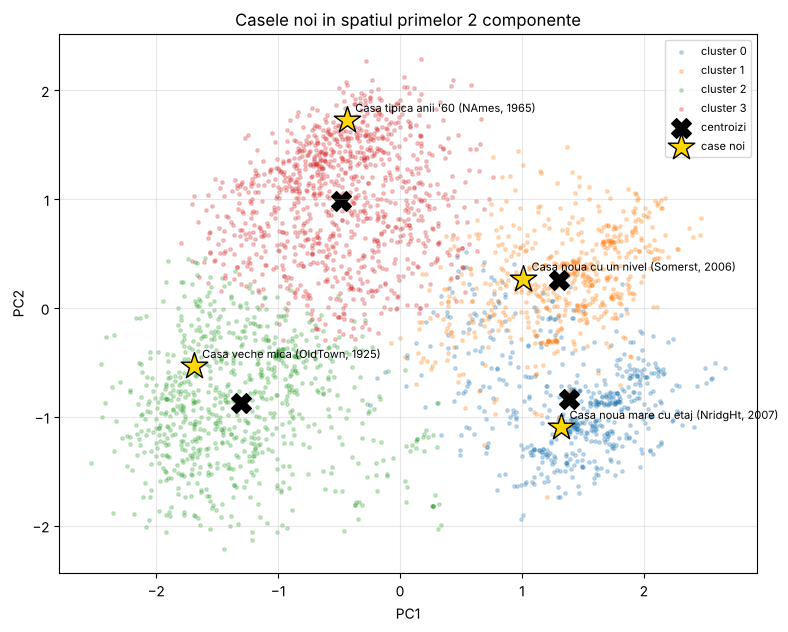

In [11]:
X_new, _, _ = build_features(new_houses)        # aceleasi completari si coloane ca la antrenare
X_new_scaled = pd.DataFrame(pipeline_km.transform(X_new),   # encoding + scalare invatate pe datele reale
                            columns=X_km.columns, index=X_new.index)  # (doar transform, nu fit)
X_new_pca = pca_km.transform(X_new_scaled)       # aceleasi componente principale
new_clusters = kmeans.predict(X_new_pca)

dist = kmeans.transform(X_new_pca)               # distanta pana la fiecare centroid
result = pd.DataFrame({"cluster": new_clusters,
                       "PC1": X_new_pca[:, 0].round(2), "PC2": X_new_pca[:, 1].round(2),
                       "distanta la centroid": dist.min(axis=1).round(2)}, index=new_houses.index)
display(result)

plt.figure(figsize=(9, 7))
for k in range(K):
    m = labels == k
    plt.scatter(X_km_pca[m, 0], X_km_pca[m, 1], s=6, alpha=0.25, label=f"cluster {k}")
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], marker="X", s=200, c="black",
            label="centroizi")
plt.scatter(X_new_pca[:, 0], X_new_pca[:, 1], marker="*", s=400, c="gold", edgecolors="black", label="case noi")
for name, (x0, y0) in zip(new_houses.index, X_new_pca[:, :2]):
    plt.annotate(name, (x0, y0), xytext=(6, 6), textcoords="offset points", fontsize=8)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Casele noi in spatiul primelor 2 componente")
plt.legend(loc="best", fontsize=8)
plt.grid(alpha=0.3)
plt.show()

Interpretarea caselor noi

Toate cele patru case inventate au ajuns în clusterul la care ne așteptam:
- Casa veche mică din OldTown (1925, fundație din cărămidă, garaj separat) este în clusterul 2, al caselor vechi. Are PC1 = -1,69, la capătul „vechi” al axei.
- Casa tipică din anii '60 din NAmes (un nivel, fundație din blocuri) este în clusterul 3, al caselor cu un nivel din anii 1950–1970. Are PC2 = 1,73, valoarea mare pe axa „un nivel”.
- Casa nouă cu un nivel din Somerst (2006) este în clusterul 1, al caselor noi cu un nivel.
- Casa nouă mare cu etaj din NridgHt (2007) este în clusterul 0, al caselor noi cu etaj. Are PC1 = 1,32 (nouă) și PC2 = -1,10 (cu etaj).

Rezultatul este intuitiv corect pentru că am construit casele schimbând exact caracteristicile care definesc componentele: anul, fundația, exteriorul, garajul și numărul de niveluri. Testul arată însă și o limită: dacă am fi schimbat doar suprafața sau calitatea, păstrând restul, clusterul ar fi rămas probabil același, pentru că aceste variabile au o influență mică asupra primelor componente. Distanțele până la centroizi (2,8–3,2) sunt comparabile cu cele ale caselor reale, deci casele inventate nu sunt valori aberante.

Bonus a: scatter 3D interactiv al clusterelor, cu centroizi

Graficul arată primele 3 componente, colorate după clusterul K-Means, iar centroizii sunt marcați cu romburi negre. Centroizii au coordonate în toate componentele păstrate, iar graficul le arată doar pe primele 3.

In [12]:
pcs_km = pd.DataFrame(X_km_pca[:, :3], columns=["PC1", "PC2", "PC3"])
pcs_km["cluster"] = labels.astype(str)

fig = px.scatter_3d(pcs_km.sort_values("cluster"), x="PC1", y="PC2", z="PC3", color="cluster", opacity=0.55,
                    title=f"Clusterele K-Means pe primele 3 componente (K = {K}), cu centroizi")
fig.update_traces(marker=dict(size=3))
fig.add_trace(go.Scatter3d(x=kmeans.cluster_centers_[:, 0], y=kmeans.cluster_centers_[:, 1],
                           z=kmeans.cluster_centers_[:, 2], mode="markers",
                           marker=dict(size=10, color="black", symbol="diamond"), name="centroizi"))
fig.update_layout(height=650)
fig.show()

Interpretarea graficului 3D al clusterelor

În 3D se vede mai clar decât în 2D că datele nu formează patru „nori” separați. Casele formează o masă continuă, iar K-Means o împarte în bucăți: clusterele se ating și se întrepătrund la margini, mai ales clusterele 2 și 3 (casele vechi și cele din anii '60) și clusterele 0 și 1 (casele noi cu și fără etaj). A treia componentă ajută la separarea clusterului 1 (case noi cu un nivel, PC3 mediu 0,91) de clusterul 0 (case noi cu etaj, PC3 mediu -0,67), care în graficul 2D se suprapun parțial.

Scorul silhouette mediu pentru K = 4 este doar 0,07 (pe o scară de la -1 la 1), deci clusterele sunt slab separate. Explicația: K-Means presupune clustere aproximativ sferice, de mărimi asemănătoare, separate de spații goale, iar aici nu există asemenea spații. Casele variază continuu (ani de construcție, suprafețe, calități), iar coloanele one-hot creează multe dimensiuni cu valori 0/1.

K-Means dă totuși o împărțire utilă și ușor de interpretat, dar ar merita încercate și alte metode:
- Gaussian Mixture Models, care permit clustere alungite și de mărimi diferite și dau pentru fiecare casă o probabilitate de apartenență, nu o atribuire strictă. Asta se potrivește mai bine pentru casele de la granița dintre clustere.
- DBSCAN sau HDBSCAN, care găsesc clustere de orice formă după densitate și marchează casele izolate ca zgomot. Pe datele noastre, fără spații goale clare, ar găsi probabil un singur cluster mare.
- Un clustering pe date cu mai puține coloane one-hot (de exemplu cu encoding ordinal sau după logaritmare și standardizare), ca suprafața și calitatea să conteze mai mult.

Bonus b (partea 2): clasele de preț comparate cu clusterele

Comparăm cele două grupări ale acelorași case: tabelul arată, pentru fiecare cluster, ce procent din case cade în fiecare clasă de preț. Adjusted Rand Index (ARI) măsoară cât de mult se potrivesc două grupări: 1 înseamnă identice, 0 înseamnă o potrivire la nivelul întâmplării.

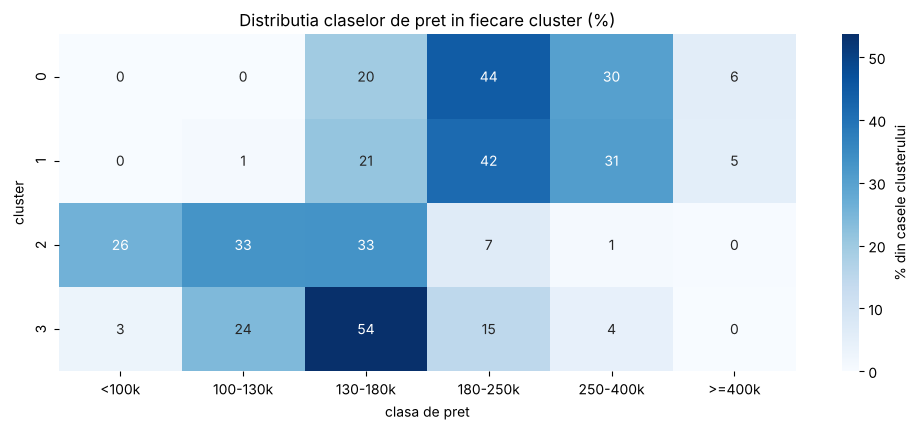

Adjusted Rand Index (clustere vs clase de pret): 0.141
Pretul median pe cluster:
0    219500.0
1    221370.0
2    122500.0
3    145000.0
Name: SalePrice, dtype: float64


In [13]:
cross = pd.crosstab(pd.Series(labels, name="cluster"),
                    pd.Series([class_names[c] for c in y], name="clasa de pret"),
                    normalize="index").reindex(columns=class_names)
plt.figure(figsize=(10, 0.6 * K + 2))
sns.heatmap(cross * 100, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% din casele clusterului"})
plt.title("Distributia claselor de pret in fiecare cluster (%)")
plt.tight_layout()
plt.show()

print(f"Adjusted Rand Index (clustere vs clase de pret): {adjusted_rand_score(y, labels):.3f}")
print("Pretul median pe cluster:")
print(df.groupby(labels)["SalePrice"].median().round(0))

Interpretarea comparației clase de preț – clustere

Adjusted Rand Index este doar 0,14: clusterele găsite de K-Means seamănă foarte puțin cu clasele de preț. Tabelul arată de ce:
- Clusterele 0 și 1 (casele noi, cu și fără etaj) au aproape aceeași distribuție de prețuri: aproximativ 20% în clasa 130–180k, 42–44% în 180–250k, 30–31% în 250–400k și 5–6% peste 400k. Cele 62 de case de peste 400k sunt aproape toate în aceste două clustere. K-Means le separă după numărul de niveluri, care nu influențează prețul.
- Clusterul 2 (case vechi) conține aproape toate casele ieftine: 26% sub 100k, 33% în 100–130k și 33% în 130–180k.
- Clusterul 3 (case cu un nivel din anii '60) este concentrat în zona de mijloc: 54% în 130–180k.

Deci clusterele ordonează casele aproximativ după preț pe axa „nou – vechi” (PC1), dar nu pot reproduce cele 6 clase, din trei motive:
- K-Means nu a văzut prețul, ci a grupat casele după ce variază cel mai mult în date.
- Prețul este determinat mai ales de calitate și suprafață: în Lab 2, `QualxLivArea`, `TotalSF` și `Overall Qual` au fost cele mai importante features pentru XGBoost și LightGBM. În schimb, primele componente principale sunt construite mai ales din variabile categorice (fundație, garaj, exterior, numărul de niveluri), pentru că după scalarea min-max acestea au cea mai mare varianță.
- Clasele de preț sunt tăieturi arbitrare pe o variabilă continuă, iar clusterele sunt grupuri de case asemănătoare ca tip. Două case din același cluster pot avea prețuri foarte diferite dacă diferă ca suprafață și calitate.

Concluzia: o structură nesupervizată găsită de PCA și K-Means nu coincide automat cu ținta care ne interesează. Pentru a obține clustere mai legate de preț, ar trebui ca variabilele importante pentru preț să aibă mai multă greutate (de exemplu prin logaritmare și standardizare, sau prin selecția features-urilor înainte de PCA).